# AI HW2 — T4 use




## 1. Install Ultralytics and verify the T4

In [ ]:
%pip -q install -U ultralytics kaggle

import torch, ultralytics, os, sys
print("Python:", sys.version.split()[0])
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("No GPU detected. In Colab choose Runtime > Change runtime type > T4 GPU, then rerun this cell.")
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
!nvidia-smi


Python: 3.13.16
Ultralytics: 8.4.213
CUDA available: True
GPU: Tesla T4
VRAM (GB): 14.56
Sun Nov 15 00:37:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |        

## 2. Authenticate with Kaggle and download the competition data




In [ ]:
import os, subprocess, zipfile, shutil
from pathlib import Path

COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"
ROOT = Path("/content/data")
ZIP_PATH = Path("/content") / f"{COMPETITION}.zip"

from google.colab import userdata


os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

def has_competition_data(p: Path) -> bool:
    return (p / "test_images.csv").exists() and (p / "train" / "images").is_dir() and (p / "val" / "images").is_dir()

if has_competition_data(ROOT):
    print("Competition data already exists at:", ROOT)
else:
    token = None
    try:
        from google.colab import userdata
        token = userdata.get("KAGGLE_API_TOKEN")
    except Exception:
        token = None

    if token:
        os.environ["KAGGLE_API_TOKEN"] = token
        print("Kaggle authentication loaded from Colab Secrets.")
    else:
        from google.colab import files
        print("No KAGGLE_API_TOKEN Colab Secret found. Upload your legacy kaggle.json file.")
        uploaded = files.upload()
        if "kaggle.json" not in uploaded:
            raise FileNotFoundError("Please upload a file named kaggle.json.")
        kaggle_dir = Path.home() / ".kaggle"
        kaggle_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2("kaggle.json", kaggle_dir / "kaggle.json")
        os.chmod(kaggle_dir / "kaggle.json", 0o600)
        Path("kaggle.json").unlink(missing_ok=True)
        print("Legacy Kaggle credentials configured.")

    subprocess.run(
        ["kaggle", "competitions", "download", "-c", COMPETITION, "-p", "/content"],
        check=True,
    )
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f"Expected Kaggle archive was not created: {ZIP_PATH}")
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(ROOT)
    print("Extracted competition archive to:", ROOT)
    print("Top-level extracted entries:", sorted(p.name for p in ROOT.iterdir())[:30])

print("Download / existing-data check complete.")


Competition data already exists at: /content/data
Download / existing-data check complete.


## 3. Mount Drive and locate the dataset

In [ ]:
from google.colab import drive
from pathlib import Path
import os

drive.mount("/content/drive")

REQUIRED = [
    "test_images.csv",
    "train/annotations_coco.json",
    "train/images",
    "train/labels",
    "val/annotations_coco.json",
    "val/images",
    "val/labels",
]

def is_dataset_root(p: Path) -> bool:
    return p.is_dir() and all((p / item).exists() for item in REQUIRED)

candidates = [
    Path("/content/data"),
    Path("/content/dataset"),
    Path("/content/competition_data"),
    Path("/content"),
    Path("/content/drive/MyDrive/data"),
    Path("/content/drive/MyDrive/dataset"),
]
# Check common extraction layouts one and two directory levels below /content/MyDrive.
for parent in (Path("/content"), Path("/content/drive/MyDrive")):
    if parent.exists():
        for child in parent.iterdir():
            if child.is_dir():
                candidates.append(child)
                for grandchild in child.iterdir():
                    if grandchild.is_dir():
                        candidates.append(grandchild)

ROOT = next((p.resolve() for p in candidates if is_dataset_root(p)), None)
if ROOT is None:
    print("Could not auto-detect the dataset. Top-level /content entries:")
    print([p.name for p in Path("/content").iterdir()])
    raise FileNotFoundError(
        "Set ROOT manually to the directory containing test_images.csv and train/, val/, test/. "
        "Example: ROOT = Path('/content/data')"
    )

print("Dataset root:", ROOT)
print("Dataset is on Drive:", str(ROOT).startswith("/content/drive/"))
print("Root entries:", sorted(p.name for p in ROOT.iterdir()))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root: /content/data
Dataset is on Drive: False
Root entries: ['test', 'test_images.csv', 'train', 'val']


## 4. Reproducibility, paths, and class IDs

In [ ]:
import json, random, shutil, subprocess, math
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw
from collections import Counter
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Keep temporary lists/configs on local Colab disk; keep models/results on Drive.
WORK = Path("/content/ai_hw2_work")
WORK.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = Path("/content/drive/MyDrive/AI_HW2_T4")
DRIVE_WORK.mkdir(parents=True, exist_ok=True)
RUNS_DIR = DRIVE_WORK / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"
SUBMISSION_NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
# `motorcycle` is the COCO-pretrained class name; class index 7 remains the competition's `motor`.
TRAIN_NAMES = SUBMISSION_NAMES.copy()
TRAIN_NAMES[7] = "motorcycle"

print("Class IDs:", dict(enumerate(SUBMISSION_NAMES)))


Class IDs: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'van', 4: 'truck', 5: 'tricycle', 6: 'bus', 7: 'motor'}


## 5. Quick dataset sanity check

In [ ]:
for split in ("train", "val"):
    assert (ROOT / split / "images").is_dir()
    assert (ROOT / split / "labels").is_dir()
    assert (ROOT / split / "annotations_coco.json").exists()

train_csv = pd.read_csv(ROOT / "test_images.csv")
assert {"image_id", "file_name", "width", "height"}.issubset(train_csv.columns)
print("Test images:", len(train_csv))
print("Train frame count:", sum(1 for _ in (ROOT / "train/images").glob("*/*.jpg")))
print("Val frame count:", sum(1 for _ in (ROOT / "val/images").glob("*/*.jpg")))

with open(ROOT / "train/annotations_coco.json", "r", encoding="utf-8") as f:
    coco_train = json.load(f)
anns = pd.DataFrame(coco_train["annotations"])
if not anns.empty:
    boxes = pd.DataFrame(anns["bbox"].tolist(), columns=["x", "y", "w", "h"], index=anns.index)
    anns = pd.concat([anns, boxes], axis=1)
    anns["sqrt_area"] = np.sqrt(anns["w"].clip(lower=0) * anns["h"].clip(lower=0))
    regular = anns[anns["iscrowd"] == 0]
    ignored = anns[anns["iscrowd"] == 1]
    print("Regular objects:", len(regular), "| ignored regions:", len(ignored))
    print("Object sqrt(area) quantiles in original pixels:")
    display(regular["sqrt_area"].quantile([.05, .25, .50, .75, .95]).round(1))
    print("Class counts (COCO category IDs 1..8):")
    display(regular["category_id"].value_counts().sort_index())

# Train and val are supplied as separate clip-level splits by the assignment.


Test images: 3811
Train frame count: 24201
Val frame count: 2846
Regular objects: 1105516 | ignored regions: 510744
Object sqrt(area) quantiles in original pixels:


,sqrt_area
0.05,19.7
0.25,32.0
0.50,45.8
0.75,67.9
0.95,130.2


Class counts (COCO category IDs 1..8):


,count
category_id,
1,328701
2,40255
3,505301
4,46940
5,30498
6,41349
7,9653
8,102819


## 5. Visually verify one ground-truth image

train: uav0000013_00000_v/0000101.jpg | green=target, orange=ignore


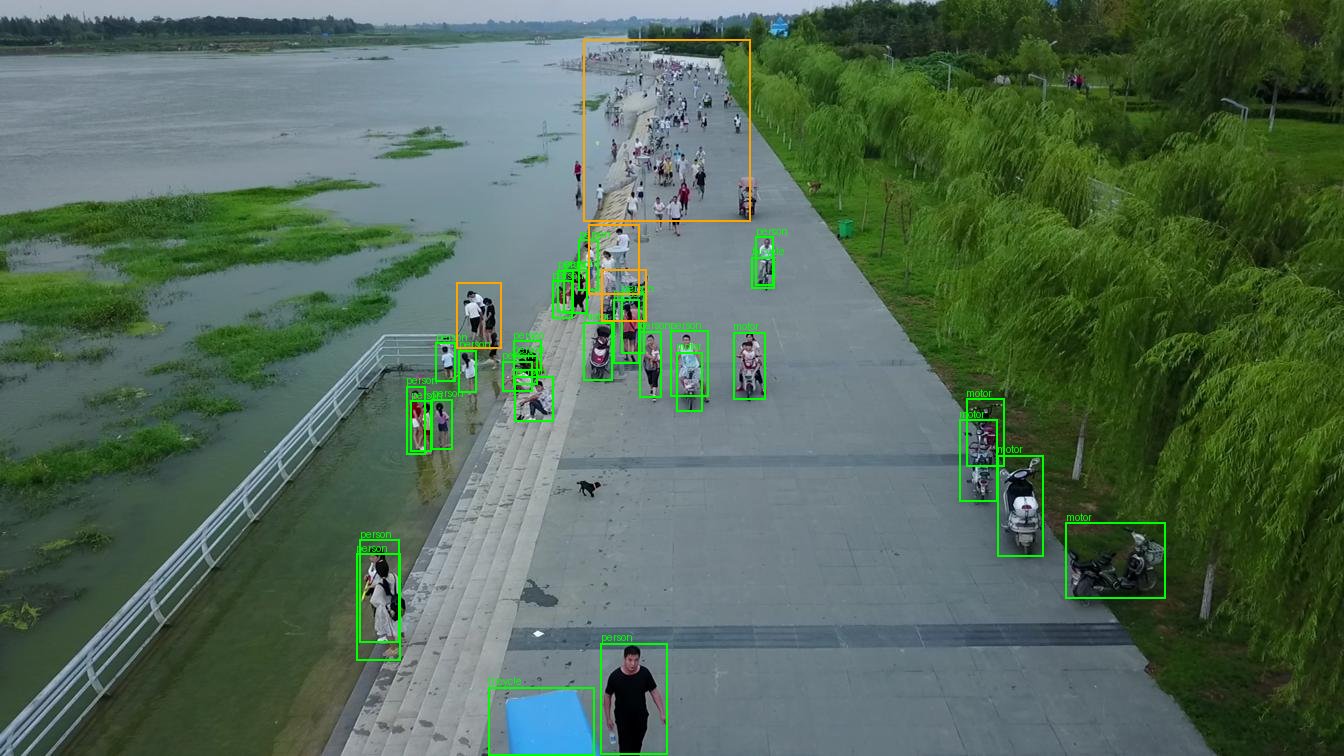

In [ ]:
def show_ground_truth(split="train", index=0):
    image_paths = []
    for clip_dir in sorted((ROOT / split / "images").iterdir()):
        image_paths.extend(sorted(clip_dir.glob("*.jpg"), key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem))
    if not image_paths:
        raise FileNotFoundError(f"No JPG frames in {ROOT / split / 'images'}")
    image_path = image_paths[index % len(image_paths)]
    clip = image_path.parent.name
    label_path = ROOT / split / "labels" / clip / f"{image_path.stem}.txt"
    ignore_path = ROOT / split / "ignore" / clip / f"{image_path.stem}.txt"
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    W, H = image.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            vals = line.split()
            if len(vals) != 5: continue
            cls, cx, cy, bw, bh = map(float, vals)
            x1, y1 = (cx-bw/2)*W, (cy-bh/2)*H
            x2, y2 = (cx+bw/2)*W, (cy+bh/2)*H
            draw.rectangle((x1, y1, x2, y2), outline="lime", width=2)
            draw.text((x1, max(0, y1-12)), SUBMISSION_NAMES[int(cls)], fill="lime")
    if ignore_path.exists():
        for line in ignore_path.read_text().splitlines():
            vals = line.split()
            if len(vals) != 4: continue
            cx, cy, bw, bh = map(float, vals)
            x1, y1 = (cx-bw/2)*W, (cy-bh/2)*H
            x2, y2 = (cx+bw/2)*W, (cy+bh/2)*H
            draw.rectangle((x1, y1, x2, y2), outline="orange", width=2)
    print(f"{split}: {clip}/{image_path.name} | green=target, orange=ignore")
    display(image)

show_ground_truth("train", 100)


## 6. Build image lists (sequence-safe)

In [ ]:
def frame_list(split, step=1):
    paths = []
    image_root = ROOT / split / "images"
    for clip_dir in sorted(image_root.iterdir()):
        frames = sorted(clip_dir.glob("*.jpg"), key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem)
        paths.extend(str(p.resolve()) for p in frames[::step])
    return paths

TRAIN_STEP = 3       # approximately 8k / 24k train frames; avoids adjacent near-duplicates
VAL_STEP = 6         # lighter validation during each epoch; full val is evaluated later
train_paths = frame_list("train", TRAIN_STEP)
val_paths = frame_list("val", VAL_STEP)
val_full_paths = frame_list("val", 1)
assert train_paths and val_paths and val_full_paths

(WORK / "train_list.txt").write_text("\n".join(train_paths))
(WORK / "val_list.txt").write_text("\n".join(val_paths))
(WORK / "val_full_list.txt").write_text("\n".join(val_full_paths))

data_config = {
    "path": str(ROOT),
    "train": str(WORK / "train_list.txt"),
    "val": str(WORK / "val_list.txt"),
    "names": {i: name for i, name in enumerate(TRAIN_NAMES)},
}
DATA_YAML = WORK / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump(data_config, sort_keys=False))

print(f"Train images used: {len(train_paths):,} (stride {TRAIN_STEP})")
print(f"Epoch validation images: {len(val_paths):,} (stride {VAL_STEP})")
print(f"Full validation images: {len(val_full_paths):,}")
print(DATA_YAML.read_text())


Train images used: 8,090 (stride 3)
Epoch validation images: 477 (stride 6)
Full validation images: 2,846
path: /content/data
train: /content/ai_hw2_work/train_list.txt
val: /content/ai_hw2_work/val_list.txt
names:
  0: person
  1: bicycle
  2: car
  3: van
  4: truck
  5: tricycle
  6: bus
  7: motorcycle



## 7. Train YOLO11s on the T4

**T4-safe starting point:** 1,280 px, batch 4, mixed precision, 2 data-loader workers. If you see CUDA out-of-memory, change `BATCH = 2` and rerun the training cell with a new run name. Training uses the full stride-3 list (`fraction=1.0`), not a smoke-test fraction.



In [ ]:
MODEL_WEIGHTS = "yolo11s.pt"
IMGSZ = 1280
BATCH = 4
EPOCHS = 35
TRAIN_HOURS = 5.5
RUN_NAME = "yolo11s_1280_T4_stride3"
RUN_DIR = RUNS_DIR / RUN_NAME
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

model = YOLO(MODEL_WEIGHTS)  # pretrained COCO weights
train_results = model.train(
    data=str(DATA_YAML),
    imgsz=IMGSZ,
    batch=BATCH,
    epochs=EPOCHS,
    time=TRAIN_HOURS,
    fraction=1.0,
    patience=8,
    workers=2,
    device=0,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    warmup_epochs=2.0,
    mosaic=1.0,
    close_mosaic=6,
    mixup=0.0,
    degrees=2.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.35,
    max_det=500,
    seed=SEED,
    deterministic=False,
    amp=True,
    cache=False,
    plots=False,
    save=True,
    save_period=-1,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    verbose=True,
)

assert BEST_WEIGHTS.exists() or LAST_WEIGHTS.exists(), "No checkpoint found. Inspect the training output."
print("Best:", BEST_WEIGHTS if BEST_WEIGHTS.exists() else "not created yet")
print("Last:", LAST_WEIGHTS if LAST_WEIGHTS.exists() else "not created yet")


Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=6, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/ai_hw2_work/data.yaml, degrees=2.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.35, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_1280_T4_stride3, nbs=64, nms=None, opset=None, op

## 8. Resume after a Colab reset (only if needed)

After reconnecting: rerun cells 1–6 to mount Drive, find the dataset and rebuild the YAML. Then run this cell instead of restarting training. It resumes from `last.pt`, restoring optimizer and scheduler state. Skip this cell if the previous training run completed normally.

In [ ]:
RUN_NAME = "yolo11s_1280_T4_stride3"
RUN_DIR = RUNS_DIR / RUN_NAME
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

if not LAST_WEIGHTS.exists():
    raise FileNotFoundError(f"No resumable checkpoint at {LAST_WEIGHTS}")
resume_model = YOLO(str(LAST_WEIGHTS))
resume_results = resume_model.train(resume=True)


WARNING ⚠️ model '/content/drive/MyDrive/AI_HW2_T4/runs/yolo11s_1280_T4_stride3/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, 

## 9. Evaluate the best model on the full validation split

In [ ]:
RUN_NAME = "yolo11s_1280_T4_stride3"
RUN_DIR = RUNS_DIR / RUN_NAME
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError("best.pt was not created; use last.pt only if training was interrupted before the first best checkpoint.")

detector = YOLO(str(BEST_WEIGHTS))
full_val_config = dict(data_config)
full_val_config["val"] = str(WORK / "val_full_list.txt")
FULL_VAL_YAML = WORK / "data_full_val.yaml"
FULL_VAL_YAML.write_text(yaml.safe_dump(full_val_config, sort_keys=False))

val_metrics = detector.val(
    data=str(FULL_VAL_YAML),
    imgsz=1280,
    batch=1,
    workers=0,
    conf=0.001,
    iou=0.7,
    max_det=750,
    plots=False,
    device=0,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_full_val",
)
print(f"Full-val mAP50-95: {val_metrics.box.map:.6f}")
print(f"Full-val mAP50:    {val_metrics.box.map50:.6f}")
print("Per-class AP50-95:")
for class_id, ap in enumerate(val_metrics.box.maps):
    print(f"{class_id} {SUBMISSION_NAMES[class_id]}: {ap:.6f}")


Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 63.4±27.4 MB/s, size: 217.5 KB)
val: Scanning /content/data/val/labels/uav0000086_00000_v... 2846 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2846/2846 456.2it/s 6.2s
val: New cache created: /content/data/val/labels/uav0000086_00000_v.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2846/2846 16.3it/s 2:55
                   all       2846     114132      0.581      0.445      0.448      0.236
                person       2776      50312      0.563      0.661       0.64      0.269
               bicycle        982       6022      0.758      0.426      0.557      0.246
                   car       2382      31821      0.762      0.569      0.598      0.388
                   van       2266       6842 

## 10. Diagnose the confidence cutoff on validation predictions

Do not submit 500 boxes per image simply because 500 is allowed. This diagnostic shows how many detections remain at different confidence cutoffs. It is a sanity check, not a replacement for mAP evaluation. For AP-style scoring, keep the cutoff low enough to retain recall; begin with 0.001 unless the detector is saturating the 500-box limit on many validation images.

In [ ]:
diag_paths = random.sample(val_full_paths, k=min(160, len(val_full_paths)))
raw_val_predictions = detector.predict(
    diag_paths,
    imgsz=1024,
    conf=0.001,
    iou=0.65,
    max_det=750,
    batch=1,
    half=True,
    device=0,
    verbose=False,
)

rows = []
for threshold in (0.001, 0.003, 0.005, 0.01, 0.025, 0.05):
    counts = []
    for result in raw_val_predictions:
        if result.boxes is None:
            counts.append(0)
        else:
            counts.append(int((result.boxes.conf >= threshold).sum().item()))
    rows.append({
        "conf": threshold,
        "mean_boxes": float(np.mean(counts)),
        "median_boxes": float(np.median(counts)),
        "p95_boxes": float(np.quantile(counts, 0.95)),
        "images_at_500": int(np.sum(np.asarray(counts) >= 500)),
    })
display(pd.DataFrame(rows))

# Save a few validation prediction images for a quick visual check.
_ = detector.predict(
    diag_paths[:8], imgsz=1024, conf=0.01, iou=0.9, max_det=500,
    batch=4, half=True, device=0, save=True,
    project=str(RUNS_DIR), name=f"{RUN_NAME}_val_examples", verbose=False
)


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


,conf,mean_boxes,median_boxes,p95_boxes,images_at_500
0,0.001,378.81250,445.0,742.40,76
1,0.003,242.23750,258.0,521.25,15
2,0.005,195.90000,207.5,430.10,1
3,0.010,147.84375,148.5,335.00,0
4,0.025,102.26875,95.0,231.65,0
5,0.050,76.50000,72.5,180.55,0


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Results saved to /content/drive/MyDrive/AI_HW2_T4/runs/yolo11s_1280_T4_stride3_val_examples-9


## 11. Generate the test submission (original-image pixel coordinates)

In [ ]:
test = pd.read_csv(ROOT / "test_images.csv")
assert test["image_id"].is_unique
assert test["file_name"].notna().all()

sample_path = ROOT / "sample_submission.csv"
if sample_path.exists():
    submission_order = pd.read_csv(sample_path)["image_id"].tolist()
else:
    submission_order = test["image_id"].tolist()
assert set(test["image_id"]) == set(submission_order)

# AP-oriented starting cutoff. Raise slightly only if validation showed widespread 500-box saturation.
CONF = 0.001
NMS_IOU = 0.65
MAX_DET = 750
PRED_BATCH = 1

image_paths = [str((ROOT / p).resolve()) for p in test["file_name"]]
missing = [p for p in image_paths if not Path(p).exists()]
assert not missing, f"Missing test images, first few: {missing[:5]}"

predictions_by_id = {}
for start in range(0, len(image_paths), PRED_BATCH):
    batch_paths = image_paths[start:start + PRED_BATCH]
    batch_ids = test.iloc[start:start + PRED_BATCH]["image_id"].tolist()
    batch_results = detector.predict(
        batch_paths,
        imgsz=1280,
        conf=CONF,
        iou=NMS_IOU,
        max_det=MAX_DET,
        batch=PRED_BATCH,
        half=True,
        device=0,
        verbose=False,
    )
    if len(batch_results) != len(batch_ids):
        raise RuntimeError("Prediction count differs from input batch size")

    for image_id, result in zip(batch_ids, batch_results):
        if result.boxes is None or len(result.boxes) == 0:
            predictions_by_id[image_id] = ""
            continue
        xyxy = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)
        height, width = result.orig_shape
        parts = []
        for (x1, y1, x2, y2), score, cls_id in zip(xyxy, scores, classes):
            if not (0 <= cls_id < 8):
                continue
            x1 = float(np.clip(x1, 0, width - 1))
            y1 = float(np.clip(y1, 0, height - 1))
            x2 = float(np.clip(x2, 0, width))
            y2 = float(np.clip(y2, 0, height))
            box_w, box_h = x2 - x1, y2 - y1
            if box_w <= 0 or box_h <= 0:
                continue
            parts.append(f"{cls_id} {float(score):.5f} {x1:.1f} {y1:.1f} {box_w:.1f} {box_h:.1f}")
        predictions_by_id[image_id] = " ".join(parts)

assert set(predictions_by_id) == set(test["image_id"])
submission = pd.DataFrame({"image_id": submission_order})
submission["PredictionString"] = submission["image_id"].map(predictions_by_id).fillna("")


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## 12. Validate and save the CSV to Drive

In [ ]:
assert list(submission.columns) == ["image_id", "PredictionString"]
assert len(submission) == len(test)
assert submission["image_id"].is_unique

num_detections = submission["PredictionString"].map(lambda s: 0 if not s else len(s.split()) // 6)
assert (num_detections <= 750).all()
assert all((not s) or len(s.split()) % 6 == 0 for s in submission["PredictionString"])

print("Rows:", len(submission))
print("Empty images:", int((num_detections == 0).sum()))
print("Mean detections/image:", round(float(num_detections.mean()), 2))
print("95th percentile detections/image:", int(num_detections.quantile(.95)))
print("Images exactly at 500:", int((num_detections == 500).sum()))
display(submission.head())

SUBMISSION_PATH = DRIVE_WORK / "submission_yolo11s_t4_det700.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
print("Saved submission:", SUBMISSION_PATH)
print("Best weights:", BEST_WEIGHTS)


Rows: 3811
Empty images: 0
Mean detections/image: 345.81
95th percentile detections/image: 666
Images exactly at 500: 7


,image_id,PredictionString
0,clip_001_0000001,0 0.74756 771.0 885.0 72.0 184.5 0 0.72510 165...
1,clip_001_0000002,0 0.72852 768.0 888.0 75.0 180.0 0 0.72803 717...
2,clip_001_0000003,0 0.73926 764.2 894.0 76.5 180.0 0 0.72705 708...
3,clip_001_0000004,0 0.72412 750.8 900.8 79.5 174.0 0 0.69336 172...
4,clip_001_0000005,0 0.70557 721.5 911.2 76.5 168.0 0 0.69678 171...


Saved submission: /content/drive/MyDrive/AI_HW2_T4/submission_yolo11s_t4_det700.csv
Best weights: /content/drive/MyDrive/AI_HW2_T4/runs/yolo11s_1280_T4_stride3/weights/best.pt


## 14. Inference improvement

In [ ]:
def resolve(split, fn):
    for c in (ROOT / split / fn, ROOT / fn, ROOT / split / "images" / fn):
        if c.exists():
            return str(c.resolve())
    return None

def size_table(split):
    d = json.load(open(ROOT / split / "annotations_coco.json", encoding="utf-8"))
    t = pd.DataFrame(d["images"])[["file_name", "width", "height"]]
    t["path"] = [resolve(split, f) for f in t["file_name"]]
    t["clip"] = t["path"].map(lambda p: Path(p).parent.name if p else None)
    t["shrink"] = (1280 / t[["width", "height"]].max(axis=1)).round(2)   # у скільки разів стискається при 1280
    return t

val_sizes = size_table("val")
print("Не знайдено файлів:", int(val_sizes["path"].isna().sum()))
print(val_sizes.groupby(["width", "height", "shrink"]).agg(frames=("clip", "size"), clips=("clip", "nunique")))

print("\nTEST:")
print(test.groupby(["width", "height"]).size())







rows = []
for (w, h), g in val_sizes.dropna(subset=["path"]).groupby(["width", "height"]):
    paths = g["path"].tolist()[::3]
    lst = WORK / f"val_{w}x{h}.txt"; lst.write_text("\n".join(paths))
    cfg = dict(data_config); cfg["val"] = str(lst)
    y = WORK / f"data_val_{w}x{h}.yaml"; y.write_text(yaml.safe_dump(cfg, sort_keys=False))
    m = detector.val(data=str(y), imgsz=1280, batch=4, workers=2, conf=0.001, iou=0.7,
                     max_det=500, plots=False, verbose=False, device=0)
    rows.append({"size": f"{w}x{h}", "images": len(paths), "mAP50-95": round(m.box.map, 4), "mAP50": round(m.box.map50, 4)})
display(pd.DataFrame(rows))

Не знайдено файлів: 0
                     frames  clips
width height shrink               
1344  756    0.95       827      2
1904  1071   0.67       459      2
2688  1512   0.48       233      1
2720  1530   0.47       349      1
3840  2160   0.33       978      1

TEST:
width  height
680    382        321
960    540        279
1344   756        441
1360   764       1474
1904   1072       305
1920   1080       991
dtype: int64
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 74.9±25.2 MB/s, size: 177.7 KB)
val: Scanning /content/data/val/labels/uav0000086_00000_v... 276 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 276/276 926.6it/s 0.3s
val: New cache created: /content/data/val/labels/uav0000086_00000_v.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━

,size,images,mAP50-95,mAP50
0,1344x756,276,0.2427,0.5268
1,1904x1071,153,0.2516,0.4204
2,2688x1512,78,0.3220,0.6449
3,2720x1530,117,0.2348,0.4597
4,3840x2160,326,0.1170,0.1579


In [ ]:
configs = [
    dict(imgsz=1280, conf=0.001),               # база  
    dict(imgsz=1280, conf=0.005),               # чи шкодить вищий conf
    dict(imgsz=1536, conf=0.001),
    dict(imgsz=1920, conf=0.001, batch=2),
    dict(imgsz=2048, conf=0.001, batch=1),
    dict(imgsz=1920, conf=0.001, batch=2, augment=True),
]
rows = []
for cfg in configs:
    cfg = {"batch": 4, **cfg}
    m = detector.val(data=str(DATA_YAML), workers=2, iou=0.7, max_det=500, plots=False,
                     verbose=False, device=0, **cfg)
    rows.append({**cfg, "mAP50-95": round(m.box.map, 4), "mAP50": round(m.box.map50, 4),
                 "motor": round(m.box.maps[7], 4)})
display(pd.DataFrame(rows))

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1378.0±1812.8 MB/s, size: 588.4 KB)
val: Scanning /content/data/val/labels/uav0000086_00000_v... 477 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 477/477 964.8it/s 0.5s
val: New cache created: /content/data/val/labels/uav0000086_00000_v.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 120/120 5.8it/s 20.6s
                   all        477      19190      0.583       0.45      0.444      0.233
Speed: 3.8ms preprocess, 18.4ms inference, 0.0ms loss, 3.5ms postprocess per image
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2875.0±782.3

,batch,imgsz,conf,mAP50-95,mAP50,motor,augment
0,4,1280,0.001,0.2327,0.4436,0.1203,NaN
1,4,1280,0.005,0.2308,0.4396,0.1191,NaN
2,4,1536,0.001,0.2344,0.4461,0.1208,NaN
3,2,1920,0.001,0.2177,0.4227,0.1141,NaN
4,1,2048,0.001,0.2162,0.4190,0.1146,NaN
5,2,1920,0.001,0.2387,0.4464,0.1127,True


In [ ]:
train_sizes = size_table("train")
tr = train_sizes.groupby(["width", "height"]).agg(train_frames=("clip", "size"), train_clips=("clip", "nunique"))
te = test.groupby(["width", "height"]).size().rename("test_frames")
display(tr.join(te, how="outer").fillna(0).astype(int))



sub = val_sizes[val_sizes["width"] <= 1904]["path"].tolist()[::3]
lst = WORK / "val_le1904.txt"; lst.write_text("\n".join(sub))
cfg_y = dict(data_config); cfg_y["val"] = str(lst)
Y = WORK / "data_val_le1904.yaml"; Y.write_text(yaml.safe_dump(cfg_y, sort_keys=False))
print("images:", len(sub))

train_frames  train_clips  test_frames
width height                                        
680   382                0            0          321
960   540                0            0          279
1344  756             5645           11          441
1360  764                0            0         1474
      765              962            1            0
1904  1071           12895           30            0
      1072               0            0          305
1920  1080             721            1          991
2688  1512            3505           11            0
2720  1530             473            2            0

images: 429


In [ ]:
configs = [
    dict(imgsz=1280, augment=True),
    dict(imgsz=1536, augment=True),
    dict(imgsz=1664, augment=True),
    dict(imgsz=1536, augment=True, iou=0.6),
]
rows = []
for cfg in configs:
    cfg = {"batch": 2, "iou": 0.7, **cfg}
    m = detector.val(data=str(Y), workers=2, conf=0.001, max_det=500, plots=False,
                     verbose=False, device=0, **cfg)
    rows.append({**cfg, "mAP50-95": round(m.box.map, 4), "mAP50": round(m.box.map50, 4),
                 "motor": round(m.box.maps[7], 4)})
display(pd.DataFrame(rows))

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1984.7±1115.0 MB/s, size: 193.2 KB)
val: Scanning /content/data/val/labels/uav0000086_00000_v... 429 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 429/429 1.0Kit/s 0.4s
val: New cache created: /content/data/val/labels/uav0000086_00000_v.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 215/215 8.3it/s 25.9s
                   all        429      19729      0.601      0.466      0.468      0.251
Speed: 2.5ms preprocess, 47.0ms inference, 0.0ms loss, 2.3ms postprocess per image
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3290.3±744.2 

,batch,iou,imgsz,augment,mAP50-95,mAP50,motor
0,2,0.7,1280,True,0.2514,0.4680,0.0870
1,2,0.7,1536,True,0.2594,0.4755,0.0901
2,2,0.7,1664,True,0.2565,0.4735,0.0917
3,2,0.6,1536,True,0.2624,0.4874,0.0917


In [ ]:
import cv2
LOW = Path("/content/lowres")
base = val_sizes[val_sizes["width"] <= 1904]
lowres_yaml = {}

for tw in (960, 680):
    img_dir, lab_dir = LOW / str(tw) / "images", LOW / str(tw) / "labels"
    out = []
    for _, r in base.iloc[::9].iterrows():            # ≈140 кадрів
        clip, stem = r["clip"], Path(r["path"]).stem
        (img_dir / clip).mkdir(parents=True, exist_ok=True)
        (lab_dir / clip).mkdir(parents=True, exist_ok=True)
        im = cv2.imread(r["path"]); h, w = im.shape[:2]
        im = cv2.resize(im, (tw, round(h * tw / w)), interpolation=cv2.INTER_AREA)
        dst = img_dir / clip / f"{stem}.jpg"; cv2.imwrite(str(dst), im)
        src = ROOT / "val" / "labels" / clip / f"{stem}.txt"
        (lab_dir / clip / f"{stem}.txt").write_text(src.read_text() if src.exists() else "")
        out.append(str(dst))
    lst = WORK / f"val_low{tw}.txt"; lst.write_text("\n".join(out))
    c = dict(data_config); c["val"] = str(lst)
    y = WORK / f"data_val_low{tw}.yaml"; y.write_text(yaml.safe_dump(c, sort_keys=False))
    lowres_yaml[tw] = y

rows = []
for tw, sizes in ((960, (960, 1280)), (680, (704, 960, 1280))):
    for s in sizes:
        m = detector.val(data=str(lowres_yaml[tw]), imgsz=s, batch=4, workers=2, conf=0.001,
                         iou=0.7, max_det=500, plots=False, verbose=False, device=0)
        rows.append({"frame_width": tw, "imgsz": s, "mAP50-95": round(m.box.map, 4), "mAP50": round(m.box.map50, 4)})
display(pd.DataFrame(rows))

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2925.3±547.8 MB/s, size: 201.6 KB)
val: Scanning /content/lowres/960/labels/uav0000086_00000_v... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 1.5Kit/s 0.1s
val: New cache created: /content/lowres/960/labels/uav0000086_00000_v.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 12.1it/s 3.0s
                   all        143       6582      0.622      0.446      0.474      0.256
Speed: 1.2ms preprocess, 11.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2224.3±580.0

,frame_width,imgsz,mAP50-95,mAP50
0,960,960,0.2558,0.4744
1,960,1280,0.2462,0.4613
2,680,704,0.2057,0.3886
3,680,960,0.2394,0.4476
4,680,1280,0.2321,0.4370


In [ ]:
configs = [
    dict(imgsz=1280, augment=False, iou=0.7),
    dict(imgsz=1536, augment=False, iou=0.7),
    dict(imgsz=1536, augment=False, iou=0.6),
]
rows = []
for cfg in configs:
    m = detector.val(data=str(Y), batch=2, workers=2, conf=0.001, max_det=500, plots=False,
                     verbose=False, device=0, **cfg)
    rows.append({**cfg, "mAP50-95": round(m.box.map, 4), "mAP50": round(m.box.map50, 4),
                 "motor": round(m.box.maps[7], 4)})
display(pd.DataFrame(rows))

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2504.9±474.5 MB/s, size: 157.6 KB)
val: Scanning /content/data/val/labels/uav0000086_00000_v.cache... 429 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 429/429 100.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 215/215 15.6it/s 13.8s
                   all        429      19729      0.637      0.439      0.463      0.247
Speed: 2.6ms preprocess, 18.2ms inference, 0.0ms loss, 2.3ms postprocess per image
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2311.5±450.9 MB/s, size: 184.8 KB)
val: Scanning /content/data/val/labels/uav00

,imgsz,augment,iou,mAP50-95,mAP50,motor
0,1280,False,0.7,0.2474,0.4630,0.0928
1,1536,False,0.7,0.2521,0.4663,0.0947
2,1536,False,0.6,0.2540,0.4732,0.0956


In [ ]:
test["path"] = [str((ROOT / p).resolve()) for p in test["file_name"]]
test["imgsz"] = np.where(test["width"] <= 960, 960, 1536)
test["aug"] = test["width"] > 960         
IOU_NMS, CONF, PRED_BATCH = 0.6, 0.001, 2

sample_path = ROOT / "sample_submission.csv"
submission_order = pd.read_csv(sample_path)["image_id"].tolist() if sample_path.exists() else test["image_id"].tolist()

predictions_by_id = {}
for (imgsz, aug), g in test.groupby(["imgsz", "aug"]):
    ids, paths = g["image_id"].tolist(), g["path"].tolist()
    print("group", imgsz, aug, len(paths))
    for s in range(0, len(paths), PRED_BATCH):
        res = detector.predict(paths[s:s+PRED_BATCH], imgsz=int(imgsz), augment=bool(aug), conf=CONF,
                               iou=IOU_NMS, max_det=500, batch=PRED_BATCH, device=0, verbose=False)
        for image_id, r in zip(ids[s:s+PRED_BATCH], res):
            if r.boxes is None or len(r.boxes) == 0:
                predictions_by_id[image_id] = ""; continue
            xyxy = r.boxes.xyxy.cpu().numpy(); sc = r.boxes.conf.cpu().numpy()
            cl = r.boxes.cls.cpu().numpy().astype(int)
            order = np.argsort(-sc)[:500]                      
            H, W = r.orig_shape
            parts = []
            for (x1, y1, x2, y2), score, c in zip(xyxy[order], sc[order], cl[order]):
                if not (0 <= c < 8): continue
                x1 = float(np.clip(x1, 0, W - 1)); y1 = float(np.clip(y1, 0, H - 1))
                x2 = float(np.clip(x2, 0, W));     y2 = float(np.clip(y2, 0, H))
                if x2 - x1 <= 0 or y2 - y1 <= 0: continue
                parts.append(f"{c} {float(score):.5f} {x1:.1f} {y1:.1f} {x2-x1:.1f} {y2-y1:.1f}")
            predictions_by_id[image_id] = " ".join(parts)

assert set(predictions_by_id) == set(test["image_id"])
submission = pd.DataFrame({"image_id": submission_order})
submission["PredictionString"] = submission["image_id"].map(predictions_by_id).fillna("")

group 960 False 600
group 1536 True 3211


In [ ]:
assert list(submission.columns) == ["image_id", "PredictionString"]
assert len(submission) == len(test) and submission["image_id"].is_unique

num_detections = submission["PredictionString"].map(lambda s: 0 if not s else len(s.split()) // 6)
assert (num_detections <= 500).all()
assert all((not s) or len(s.split()) % 6 == 0 for s in submission["PredictionString"])

print("Rows:", len(submission))
print("Empty images:", int((num_detections == 0).sum()))
print("Mean detections/image:", round(float(num_detections.mean()), 2))
print("95th percentile:", int(num_detections.quantile(.95)))
print("Images exactly at 500:", int((num_detections == 500).sum()))

SUBMISSION_PATH = DRIVE_WORK / "submission_yolo11s_tta1536_iou06.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
print("Saved:", SUBMISSION_PATH)

Rows: 3811
Empty images: 0
Mean detections/image: 402.68
95th percentile: 500
Images exactly at 500: 1595
Saved: /content/drive/MyDrive/AI_HW2_T4/submission_yolo11s_tta1536_iou06.csv
